# Estimation note：表格与图

为 `estimation_note.tex`（英文）与 `estimation_note_zh.tex`（中文）生成全部表格与图：
英文版写到 `tables/est_*.tex`、`figures/est_*.pdf`，中文版写到 `tables/zh/`、`figures/zh/`。
只读取 `studies/09_estimation_vs_decision/results/` 下的缓存结果，不重新模拟；
先运行该目录下的 `bias_variance.ipynb` 与 `asymptotics_check.ipynb`。

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RES = Path("../studies/09_estimation_vs_decision/results")
OUT = Path.cwd()
for sub in ["figures", "tables", "figures/zh", "tables/zh"]:
    (OUT / sub).mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42})
# 中文版图表：临时换成含中文字形的字体（与 research_note.ipynb 相同）
RC = {"en": {}, "zh": {"font.sans-serif": ["Arial Unicode MS"], "axes.unicode_minus": False}}
C_G, C_TY, C_HS = "#2a78d6", "#1baf7a", "#eb6834"

DGPS = ["高斯", "t(15)", "t(8)", "t(5)", "t(4)", "t(3)", "崩盘混合"]
QS = [0.95, 0.975, 0.99]

# 两种语言的标签
L = {
    "en": dict(
        name={"高斯": "Gaussian", "t(3)": "$t_3$", "t(4)": "$t_4$", "t(5)": "$t_5$", "t(8)": "$t_8$",
              "t(15)": "$t_{15}$", "崩盘混合": "Crash mixture"},
        plain={"高斯": "Gaussian", "t(3)": "t(3)", "t(4)": "t(4)", "t(5)": "t(5)", "t(8)": "t(8)",
               "t(15)": "t(15)", "崩盘混合": "Crash mixture"},
        dgp="DGP", level=r"Level: $\mathrm{ES}(L_{\mathrm{EW}})$", shape=r"Shape: ES ratio $\theta$",
        gplug="Gaussian plug-in", bias="bias", sd="sd", rmse=r"RMSE (\%), $T=1000$", tvar=r"$T\cdot\mathrm{Var}$, $T=4000$",
        theory="Theory", gauss="Gauss", pred="Predicted (sample cov.)", scov="Sample cov.", scov_long="Sample covariance",
        width=r"\emph{Median width (\% of $\theta$), $T=4000$}",
        fig_note="Solid: simulated $T\\cdot\\mathrm{Var}(\\hat\\theta/\\theta-1)$\nDashed: asymptotic variance\nSample cov. has no finite\nasymptotic variance for $\\nu\\leq 4$\n$q=0.95$, 5000 reps per point",
        days="$T$ (days)", ylab="RMSE of ES ratio (%)"),
    "zh": dict(
        name={"高斯": "高斯", "t(3)": "$t_3$", "t(4)": "$t_4$", "t(5)": "$t_5$", "t(8)": "$t_8$",
              "t(15)": "$t_{15}$", "崩盘混合": "崩盘混合"},
        plain={"高斯": "高斯", "t(3)": "t(3)", "t(4)": "t(4)", "t(5)": "t(5)", "t(8)": "t(8)",
               "t(15)": "t(15)", "崩盘混合": "崩盘混合"},
        dgp="DGP", level=r"水平：$\mathrm{ES}(L_{\mathrm{EW}})$", shape=r"形状：ES 比值 $\theta$",
        gplug="高斯插件", bias="偏差", sd="标准差", rmse=r"RMSE（\%），$T=1000$", tvar=r"$T\cdot\mathrm{Var}$，$T=4000$",
        theory="理论值", gauss="高斯", pred="预测（样本协方差）", scov="样本协方差", scov_long="样本协方差",
        width=r"\emph{区间宽度中位数（占 $\theta$ 的 \%），$T=4000$}",
        fig_note="实线：模拟的 $T\\cdot\\mathrm{Var}(\\hat\\theta/\\theta-1)$\n虚线：渐近方差\n$\\nu\\leq 4$ 时样本协方差\n没有有限的渐近方差\n$q=0.95$，每点 5000 次重复",
        days="$T$ (日)", ylab="ES 比值的 RMSE (%)"),
}
SUFFIX = {"en": "", "zh": "zh/"}

TH = pd.read_csv(RES / "expD_theory.csv.gz").set_index(["dgp", "q"])
THY = pd.read_csv(RES / "expE_tyler_theory.csv.gz").set_index(["dgp", "q"])
SIM = pd.read_csv(RES / "expD_biasvar.csv.gz").merge(pd.read_csv(RES / "expE_tyler.csv.gz"), on=["dgp", "T", "rep"])
for q in QS:
    tag = f"{int(round(q * 1000))}"
    SIM[f"ty_rat_{tag}"] = SIM["tyler_ratio"] / SIM["dgp"].map(lambda k: TH.loc[(k, q), "theta"]) - 1
COV = pd.read_csv(RES / "expF_coverage.csv.gz")
print(len(SIM), "rows;", SIM.groupby(["dgp", "T"]).size().min(), "reps per cell")

210000 rows; 5000 reps per cell


In [2]:
def stats(e):
    e = np.asarray(e)
    return dict(bias=e.mean() * 100, sd=e.std(ddof=1) * 100, rmse=np.sqrt((e ** 2).mean()) * 100, var=e.var(ddof=1))


rows = []
for (k, T), g in SIM.groupby(["dgp", "T"], sort=False):
    for q in QS:
        tag = f"{int(round(q * 1000))}"
        for key in ["g_lvl", "hs_lvl", "g_rat", "ty_rat", "hs_rat"]:
            rows.append(dict(dgp=k, T=T, q=q, est=key, **stats(g[f"{key}_{tag}"])))
SUM = pd.DataFrame(rows).set_index(["dgp", "T", "q", "est"])
S = lambda k, T, q, est, f: SUM.loc[(k, T, q, est), f]


def fmt(x, d=2, sign=False):
    if not np.isfinite(x):
        return r"$\infty$"
    s = f"{x:+.{d}f}" if sign else f"{x:.{d}f}"
    return s.replace("-", "$-$").replace("+", "$+$")


def write_table(lang, name, lines):
    path = OUT / "tables" / f"{SUFFIX[lang]}{name}.tex"
    path.write_text("\n".join(lines))
    return path

## Table 1：水平与形状误差的分解（q = 0.95，T = 1000）

In [3]:
def table_decomp(lang):
    t = L[lang]
    lines = [r"\begin{tabular}{lrrrrrrrr}", r"\toprule",
             rf" & \multicolumn{{4}}{{c}}{{{t['level']}}} & \multicolumn{{4}}{{c}}{{{t['shape']}}} \\",
             r"\cmidrule(lr){2-5}\cmidrule(lr){6-9}",
             rf" & \multicolumn{{2}}{{c}}{{{t['gplug']}}} & \multicolumn{{2}}{{c}}{{HS}} & \multicolumn{{2}}{{c}}{{{t['gplug']}}} & \multicolumn{{2}}{{c}}{{HS}} \\",
             r"\cmidrule(lr){2-3}\cmidrule(lr){4-5}\cmidrule(lr){6-7}\cmidrule(lr){8-9}",
             f"{t['dgp']} & " + " & ".join([t["bias"], t["sd"]] * 4) + r" \\", r"\midrule"]
    for k in DGPS:
        v = [S(k, 1000, .95, e, f) for e in ["g_lvl", "hs_lvl", "g_rat", "hs_rat"] for f in ["bias", "sd"]]
        lines.append(t["name"][k] + " & " + " & ".join(fmt(x, 2, sign=(i % 2 == 0)) for i, x in enumerate(v)) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}"]
    return write_table(lang, "est_decomp", lines)


for lang in L:
    print(table_decomp(lang).read_text(), "\n")

\begin{tabular}{lrrrrrrrr}
\toprule
 & \multicolumn{4}{c}{Level: $\mathrm{ES}(L_{\mathrm{EW}})$} & \multicolumn{4}{c}{Shape: ES ratio $\theta$} \\
\cmidrule(lr){2-5}\cmidrule(lr){6-9}
 & \multicolumn{2}{c}{Gaussian plug-in} & \multicolumn{2}{c}{HS} & \multicolumn{2}{c}{Gaussian plug-in} & \multicolumn{2}{c}{HS} \\
\cmidrule(lr){2-3}\cmidrule(lr){4-5}\cmidrule(lr){6-7}\cmidrule(lr){8-9}
DGP & bias & sd & bias & sd & bias & sd & bias & sd \\
\midrule
Gaussian & $-$0.07 & 2.25 & $-$0.63 & 3.80 & $+$0.06 & 2.11 & $+$0.13 & 3.81 \\
$t_{15}$ & $-$2.89 & 2.49 & $-$0.87 & 4.48 & $+$0.03 & 2.32 & $+$0.26 & 4.32 \\
$t_8$ & $-$5.33 & 2.82 & $-$0.81 & 5.21 & $+$0.05 & 2.60 & $+$0.13 & 4.76 \\
$t_5$ & $-$7.96 & 3.83 & $-$0.83 & 6.43 & $+$0.03 & 3.34 & $+$0.15 & 5.63 \\
$t_4$ & $-$9.15 & 5.59 & $-$0.97 & 7.56 & $+$0.17 & 4.85 & $+$0.25 & 6.14 \\
$t_3$ & $-$8.51 & 25.15 & $-$0.78 & 11.82 & $+$0.50 & 10.68 & $+$0.31 & 7.82 \\
Crash mixture & $-$14.31 & 7.86 & $-$0.81 & 12.98 & $+$9.87 & 7.14 & $+$1.14

## Table 2：三种比值估计量（q = 0.95）

In [4]:
def table_three(lang):
    t = L[lang]
    lines = [r"\begin{tabular}{lrrrrrrrrr}", r"\toprule",
             rf" & \multicolumn{{3}}{{c}}{{{t['rmse']}}} & \multicolumn{{3}}{{c}}{{{t['tvar']}}} & \multicolumn{{3}}{{c}}{{{t['theory']}}} \\",
             r"\cmidrule(lr){2-4}\cmidrule(lr){5-7}\cmidrule(lr){8-10}",
             f"{t['dgp']} & {t['gauss']} & Tyler & HS & {t['gauss']} & Tyler & HS" + r" & $V_G$ & $V_{\mathrm{Ty}}$ & $V_{HS}$ \\", r"\midrule"]
    for k in DGPS:
        r = [S(k, 1000, .95, e, "rmse") for e in ["g_rat", "ty_rat", "hs_rat"]]
        best = int(np.argmin(r))
        rs = [(r"\textbf{%s}" % fmt(x)) if i == best else fmt(x) for i, x in enumerate(r)]
        tv = [S(k, 4000, .95, e, "var") * 4000 for e in ["g_rat", "ty_rat", "hs_rat"]]
        th = [TH.loc[(k, .95), "avar_g_rat"], THY.loc[(k, .95), "avar_ty_rat"], TH.loc[(k, .95), "avar_hs_rat"]]
        ths = [fmt(x) if np.isfinite(x) else (r"$\infty$" if i == 0 else "--") for i, x in enumerate(th)]
        lines.append(t["name"][k] + " & " + " & ".join(rs + [fmt(x) for x in tv] + ths) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}"]
    return write_table(lang, "est_three", lines)


for lang in L:
    print(table_three(lang).read_text(), "\n")

\begin{tabular}{lrrrrrrrrr}
\toprule
 & \multicolumn{3}{c}{RMSE (\%), $T=1000$} & \multicolumn{3}{c}{$T\cdot\mathrm{Var}$, $T=4000$} & \multicolumn{3}{c}{Theory} \\
\cmidrule(lr){2-4}\cmidrule(lr){5-7}\cmidrule(lr){8-10}
DGP & Gauss & Tyler & HS & Gauss & Tyler & HS & $V_G$ & $V_{\mathrm{Ty}}$ & $V_{HS}$ \\
\midrule
Gaussian & \textbf{2.11} & 2.43 & 3.81 & 0.44 & 0.59 & 1.44 & 0.45 & 0.60 & 1.49 \\
$t_{15}$ & \textbf{2.32} & 2.46 & 4.33 & 0.56 & 0.62 & 1.91 & 0.53 & 0.60 & 1.87 \\
$t_8$ & 2.60 & \textbf{2.44} & 4.77 & 0.67 & 0.60 & 2.34 & 0.67 & 0.60 & 2.32 \\
$t_5$ & 3.34 & \textbf{2.46} & 5.63 & 1.24 & 0.61 & 3.08 & 1.34 & 0.60 & 3.17 \\
$t_4$ & 4.85 & \textbf{2.40} & 6.14 & 3.19 & 0.60 & 4.06 & $\infty$ & 0.60 & 3.96 \\
$t_3$ & 10.69 & \textbf{2.45} & 7.83 & 13.59 & 0.61 & 6.35 & $\infty$ & 0.60 & 6.38 \\
Crash mixture & 12.18 & 26.72 & \textbf{8.32} & 5.56 & 1.07 & 6.78 & 5.74 & -- & 6.61 \\
\bottomrule
\end{tabular} 

\begin{tabular}{lrrrrrrrrr}
\toprule
 & \multicolumn{3}{c}{RMSE

## Table 3：收敛速度（IQR 的双对数斜率）

In [5]:
def iqr_slope(k, col):
    g = SIM[SIM.dgp == k].groupby("T")[col]
    iqr = g.quantile(.75) - g.quantile(.25)
    return np.polyfit(np.log(iqr.index.to_numpy(float)), np.log(iqr.to_numpy()), 1)[0]


TS = sorted(SIM["T"].unique())


def pred(k):
    nu = {"t(3)": 3, "t(4)": 4}.get(k)
    if nu == 3:
        return -(1 - 2 / 3)
    if nu == 4:
        return -0.5 + 1 / (2 * np.mean(np.log(TS)))
    return -0.5


SLOPES = {k: [pred(k)] + [iqr_slope(k, c) for c in ["g_rat_950", "ty_rat_950", "hs_rat_950"]]
          for k in DGPS if k != "崩盘混合"}


def table_rates(lang):
    t = L[lang]
    lines = [r"\begin{tabular}{lrrrr}", r"\toprule",
             f"{t['dgp']} & {t['pred']} & {t['scov']} & Tyler & HS" + r" \\", r"\midrule"]
    for k, v in SLOPES.items():
        lines.append(t["name"][k] + " & " + " & ".join(fmt(x, 3) for x in v) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}"]
    return write_table(lang, "est_rates", lines)


for lang in L:
    print(table_rates(lang).read_text(), "\n")

\begin{tabular}{lrrrr}
\toprule
DGP & Predicted (sample cov.) & Sample cov. & Tyler & HS \\
\midrule
Gaussian & $-$0.500 & $-$0.504 & $-$0.494 & $-$0.503 \\
$t_{15}$ & $-$0.500 & $-$0.501 & $-$0.499 & $-$0.490 \\
$t_8$ & $-$0.500 & $-$0.505 & $-$0.507 & $-$0.490 \\
$t_5$ & $-$0.500 & $-$0.459 & $-$0.507 & $-$0.473 \\
$t_4$ & $-$0.424 & $-$0.431 & $-$0.514 & $-$0.477 \\
$t_3$ & $-$0.333 & $-$0.332 & $-$0.501 & $-$0.442 \\
\bottomrule
\end{tabular} 

\begin{tabular}{lrrrr}
\toprule
DGP & 预测（样本协方差） & 样本协方差 & Tyler & HS \\
\midrule
高斯 & $-$0.500 & $-$0.504 & $-$0.494 & $-$0.503 \\
$t_{15}$ & $-$0.500 & $-$0.501 & $-$0.499 & $-$0.490 \\
$t_8$ & $-$0.500 & $-$0.505 & $-$0.507 & $-$0.490 \\
$t_5$ & $-$0.500 & $-$0.459 & $-$0.507 & $-$0.473 \\
$t_4$ & $-$0.424 & $-$0.431 & $-$0.514 & $-$0.477 \\
$t_3$ & $-$0.333 & $-$0.332 & $-$0.501 & $-$0.442 \\
\bottomrule
\end{tabular} 



## Table 4：置信区间覆盖率

In [6]:
labs = ["样本协方差", "Tyler", "HS"]
cv = COV.groupby(["dgp", "T"], sort=False)[[f"cover_{l}" for l in labs]].mean() * 100
wd = COV.groupby(["dgp", "T"], sort=False)[[f"width_{l}" for l in labs]].median() * 100


def table_coverage(lang):
    t = L[lang]
    lines = [r"\begin{tabular}{lrrrrrrrrr}", r"\toprule",
             rf" & \multicolumn{{3}}{{c}}{{{t['scov_long']}}} & \multicolumn{{3}}{{c}}{{Tyler}} & \multicolumn{{3}}{{c}}{{HS}} \\",
             r"\cmidrule(lr){2-4}\cmidrule(lr){5-7}\cmidrule(lr){8-10}",
             f"{t['dgp']} & 250 & 1000 & 4000 & 250 & 1000 & 4000 & 250 & 1000 & 4000" + r" \\", r"\midrule"]
    for k in ["高斯", "t(8)", "t(5)", "t(4)", "t(3)", "崩盘混合"]:
        v = [cv.loc[(k, T), f"cover_{l}"] for l in labs for T in [250, 1000, 4000]]
        lines.append(t["name"][k] + " & " + " & ".join(f"{x:.1f}" for x in v) + r" \\")
    lines += [r"\midrule", rf"\multicolumn{{10}}{{l}}{{{t['width']}}} \\"]
    for k in ["高斯", "t(4)", "t(3)", "崩盘混合"]:
        v = [wd.loc[(k, 4000), f"width_{l}"] for l in labs]
        lines.append(t["name"][k] + "".join(rf" & \multicolumn{{3}}{{c}}{{{x:.1f}}}" for x in v) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}"]
    return write_table(lang, "est_coverage", lines)


for lang in L:
    print(table_coverage(lang).read_text(), "\n")

\begin{tabular}{lrrrrrrrrr}
\toprule
 & \multicolumn{3}{c}{Sample covariance} & \multicolumn{3}{c}{Tyler} & \multicolumn{3}{c}{HS} \\
\cmidrule(lr){2-4}\cmidrule(lr){5-7}\cmidrule(lr){8-10}
DGP & 250 & 1000 & 4000 & 250 & 1000 & 4000 & 250 & 1000 & 4000 \\
\midrule
Gaussian & 94.4 & 95.5 & 94.5 & 94.8 & 95.2 & 94.8 & 93.2 & 95.2 & 95.0 \\
$t_8$ & 94.0 & 94.0 & 94.5 & 94.5 & 94.8 & 94.2 & 93.2 & 94.5 & 94.8 \\
$t_5$ & 92.5 & 94.0 & 93.5 & 94.5 & 95.5 & 95.1 & 92.6 & 94.3 & 94.2 \\
$t_4$ & 91.9 & 93.9 & 94.5 & 94.6 & 95.7 & 94.2 & 92.7 & 95.0 & 94.7 \\
$t_3$ & 89.5 & 92.8 & 94.1 & 94.2 & 94.5 & 95.0 & 92.2 & 95.1 & 94.2 \\
Crash mixture & 61.4 & 56.5 & 29.2 & 0.4 & 0.0 & 0.0 & 84.0 & 94.0 & 94.3 \\
\midrule
\multicolumn{10}{l}{\emph{Median width (\% of $\theta$), $T=4000$}} \\
Gaussian & \multicolumn{3}{c}{4.1} & \multicolumn{3}{c}{4.8} & \multicolumn{3}{c}{7.6} \\
$t_4$ & \multicolumn{3}{c}{7.6} & \multicolumn{3}{c}{4.8} & \multicolumn{3}{c}{12.1} \\
$t_3$ & \multicolumn{3}{c}{12.1} & \

## Figure 1：T · Var 与理论渐近方差

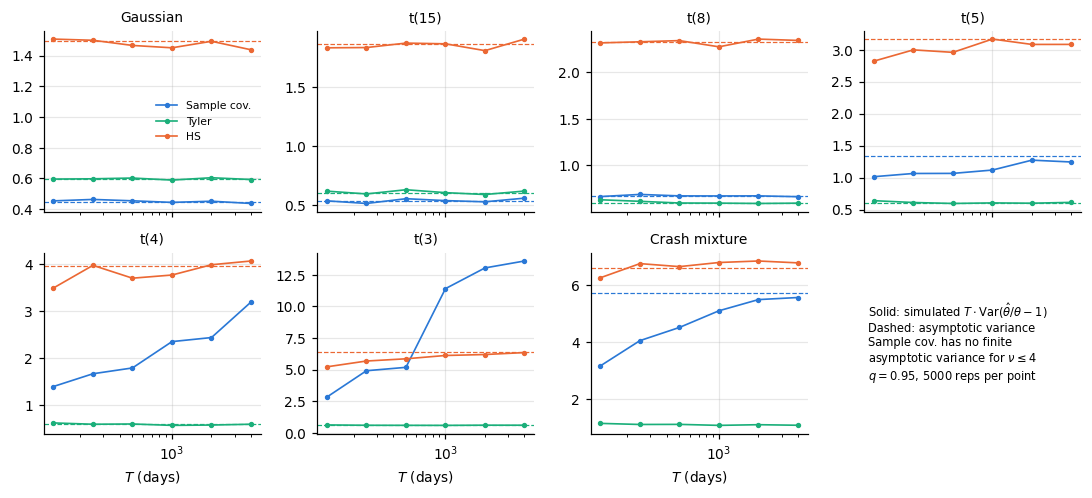

/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 39640 (\N{CJK UNIFIED IDEOGRAPH-9AD8}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 26031 (\N{CJK UNIFIED IDEOGRAPH-65AF}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 26679 (\N{CJK UNIFIED IDEOGRAPH-6837}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 26412 (\N{CJK UNIFIED IDEOGRAPH-672C}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 21327 (\N{CJK UNIFIED IDEOGRAPH-534F}) missing from font(s) DejaV

/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 23849 (\N{CJK UNIFIED IDEOGRAPH-5D29}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 30424 (\N{CJK UNIFIED IDEOGRAPH-76D8}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 28151 (\N{CJK UNIFIED IDEOGRAPH-6DF7}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 21512 (\N{CJK UNIFIED IDEOGRAPH-5408}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
Font 'default' does not have a glyph for '\u5b9e' [U+5b9e], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u7ebf' [U+7ebf], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\uff1a' [U+ff1a], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u6a21' [U+6a21], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u62df' [U+62df], substituting with a dummy symbol.


... (9 outputs left out)

Font 'default' does not have a glyph for '\u70b9' [U+70b9], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u6b21' [U+6b21], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u91cd' [U+91cd], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u590d' [U+590d], substituting with a dummy symbol.


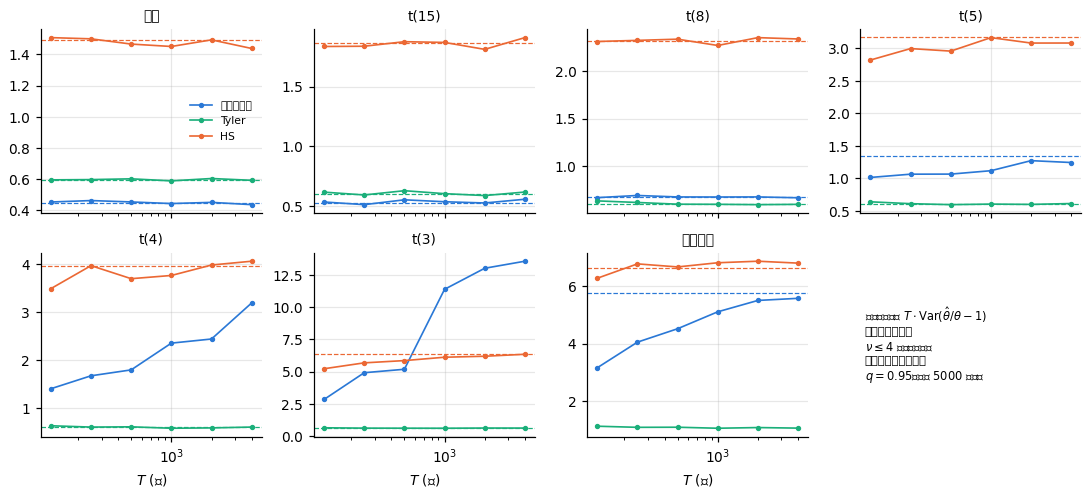

In [7]:
def fig_tvar(lang):
    t = L[lang]
    with plt.rc_context(RC[lang]):
        fig, axes = plt.subplots(2, 4, figsize=(10, 4.6), sharex=True)
        for ax, k in zip(axes.flat, DGPS[:1] + DGPS[1:]):
            for lab, c, key, th in [(t["scov"], C_G, "g_rat", TH.loc[(k, .95), "avar_g_rat"]),
                                    ("Tyler", C_TY, "ty_rat", THY.loc[(k, .95), "avar_ty_rat"]),
                                    ("HS", C_HS, "hs_rat", TH.loc[(k, .95), "avar_hs_rat"])]:
                d = SUM.xs((.95, key), level=("q", "est")).loc[k]
                ax.plot(d.index, d["var"] * d.index, "o-", color=c, ms=2.5, lw=1.1, label=lab)
                if np.isfinite(th):
                    ax.axhline(th, color=c, ls="--", lw=.8)
            ax.set_xscale("log")
            ax.set_title(t["plain"][k], fontsize=9)
        axes.flat[0].legend(fontsize=7, frameon=False)
        axes.flat[-1].axis("off")
        axes.flat[-1].text(0.02, .5, t["fig_note"], fontsize=7.5, va="center", transform=axes.flat[-1].transAxes)
        for ax in axes[1]:
            ax.set_xlabel(t["days"])
        fig.tight_layout()
        fig.savefig(OUT / "figures" / f"{SUFFIX[lang]}est_tvar.pdf", bbox_inches="tight")
    return fig


for lang in L:
    fig_tvar(lang)
plt.show()

## Figure 2：崩盘混合下的 RMSE

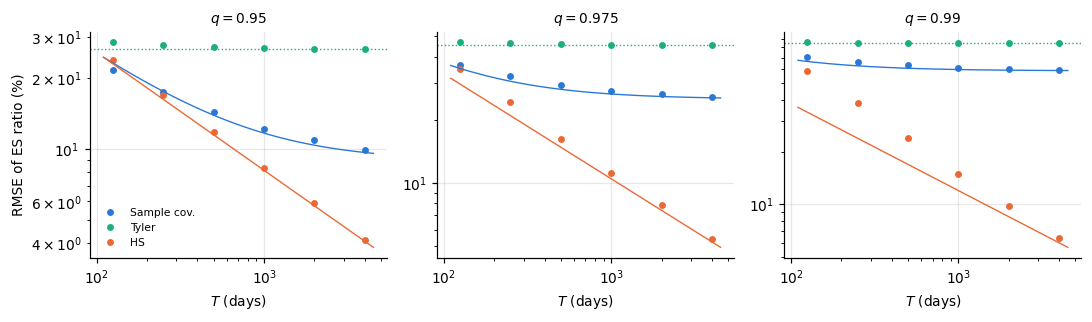

/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 27604 (\N{CJK UNIFIED IDEOGRAPH-6BD4}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 20540 (\N{CJK UNIFIED IDEOGRAPH-503C}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 30340 (\N{CJK UNIFIED IDEOGRAPH-7684}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
Font 'default' does not have a glyph for '\u65e5' [U+65e5], substituting with a dummy symbol.


/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 26679 (\N{CJK UNIFIED IDEOGRAPH-6837}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 26412 (\N{CJK UNIFIED IDEOGRAPH-672C}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 21327 (\N{CJK UNIFIED IDEOGRAPH-534F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 26041 (\N{CJK UNIFIED IDEOGRAPH-65B9}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 24046 (\N{CJK UNIFIED IDEOGRAPH-5DEE}) missing from font(s) DejaV

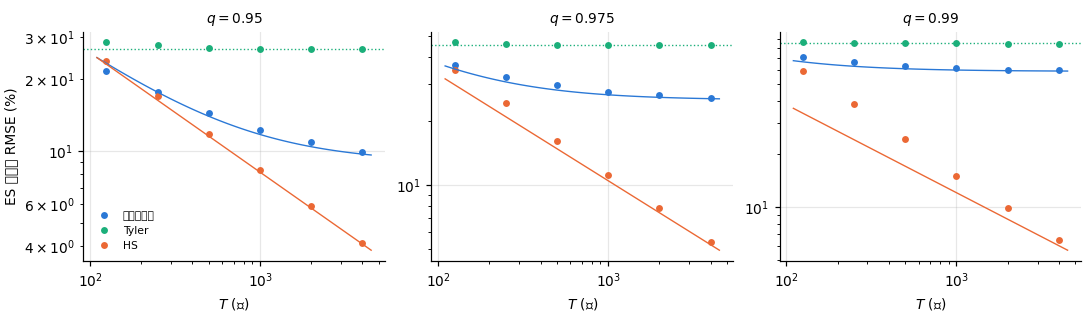

In [8]:
def fig_crash(lang):
    t = L[lang]
    Tf = np.geomspace(110, 4500, 100)
    with plt.rc_context(RC[lang]):
        fig, axes = plt.subplots(1, 3, figsize=(10, 3.0))
        for ax, q in zip(axes, QS):
            th = TH.loc[("崩盘混合", q)]
            for lab, c, key in [(t["scov"], C_G, "g_rat"), ("Tyler", C_TY, "ty_rat"), ("HS", C_HS, "hs_rat")]:
                d = SUM.xs(("崩盘混合", q, key), level=("dgp", "q", "est"))
                ax.plot(d.index, d["rmse"], "o", color=c, ms=3.5, label=lab)
            ax.plot(Tf, 100 * np.sqrt(th.abias_g_rat ** 2 + th.avar_g_rat / Tf), color=C_G, lw=.9)
            ax.plot(Tf, 100 * np.sqrt(th.avar_hs_rat / Tf), color=C_HS, lw=.9)
            ax.axhline(100 * THY.loc[("崩盘混合", q), "abias_ty_rat"], color=C_TY, lw=.9, ls=":")
            ax.set_xscale("log"); ax.set_yscale("log")
            ax.set_title(f"$q={q}$", fontsize=9); ax.set_xlabel(t["days"])
        axes[0].set_ylabel(t["ylab"])
        axes[0].legend(fontsize=7, frameon=False)
        fig.tight_layout()
        fig.savefig(OUT / "figures" / f"{SUFFIX[lang]}est_crash.pdf", bbox_inches="tight")
    return fig


for lang in L:
    fig_crash(lang)
plt.show()

## 正文引用的其他数字

In [9]:
nums = {
    "level bias t4 q95 (k ratio)": TH.loc[("t(4)", .95), "abias_g_lvl"] * 100,
    "crash abias G by q": [TH.loc[("崩盘混合", q), "abias_g_rat"] * 100 for q in QS],
    "crash abias Tyler by q": [THY.loc[("崩盘混合", q), "abias_ty_rat"] * 100 for q in QS],
    "crash T* by q": [(TH.loc[("崩盘混合", q), "avar_hs_rat"] - TH.loc[("崩盘混合", q), "avar_g_rat"]) / TH.loc[("崩盘混合", q), "abias_g_rat"] ** 2 for q in QS],
    "VG/VHS by q (Gauss)": [TH.loc[("高斯", q), "avar_g_rat"] / TH.loc[("高斯", q), "avar_hs_rat"] for q in QS],
    "level bias share T4000 t4": SUM.loc[("t(4)", 4000, .95, "g_lvl"), "bias"] ** 2 / SUM.loc[("t(4)", 4000, .95, "g_lvl"), "rmse"] ** 2,
}
for k, v in nums.items():
    print(k, np.round(v, 3))

level bias t4 q95 (k ratio) -8.922
crash abias G by q [ 8.902 25.097 58.67 ]
crash abias Tyler by q [26.606 45.433 84.464]
crash T* by q [110.141  53.849   6.433]
VG/VHS by q (Gauss) [0.3   0.207 0.119]
level bias share T4000 t4 0.888
